In [3]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import HuberRegressor
from astropy.table import Table
import os
import time

In [4]:
COSMOS_FILE = "asu.fit"

In [5]:
protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]

In [6]:
print("ucitavanje cosmos podataka")

cos = Table.read(
    COSMOS_FILE,
    format="fits"
).to_pandas()


#cosmos filteri

cos = cos[
    (cos["zphot"] > 0) &
    (cos["zphot"] < 4) &
    (cos["MassMed"] > 0) &
    (cos["SFR"] > -5)
].copy()


#cosmos velicine

cos["logM"] = cos["MassMed"]
cos["logSFR"] = cos["SFR"]


#sfms filter

cos = cos[
    cos["logSFR"] > -3.5
].copy()


print(
    f"Broj COSMOS objekata nakon filtriranja: {len(cos)}"
)

ucitavanje cosmos podataka
Broj COSMOS objekata nakon filtriranja: 491874


In [7]:
def get_cosmos_bin(z):

    if z == 0:

        return cos[
            (cos["zphot"] >= 0) &
            (cos["zphot"] < 0.5)
        ].copy()

    elif z == 1:

        return cos[
            (cos["zphot"] >= 0.5) &
            (cos["zphot"] < 1)
        ].copy()

    elif z == 2:

        return cos[
            (cos["zphot"] >= 1) &
            (cos["zphot"] < 2)
        ].copy()

    elif z == 3:

        return cos[
            (cos["zphot"] >= 2) &
            (cos["zphot"] < 4)
        ].copy()

In [8]:
cosmos_fits = {}


for z in range(4):

    cos_sub = get_cosmos_bin(z)

    if len(cos_sub) < 2:

        print(
            f"Premalo COSMOS objekata za z={z}"
        )

        continue


    X = (
        cos_sub["logM"]
        .values
        .reshape(-1, 1)
    )

    y = cos_sub["logSFR"].values


    huber = HuberRegressor()

    huber.fit(
        X,
        y
    )


    cosmos_fits[z] = huber


    print(
        f"COSMOS SFMS fit z={z}: "
        f"slope = {huber.coef_[0]:.4f}, "
        f"intercept = {huber.intercept_:.4f}"
    )

COSMOS SFMS fit z=0: slope = 0.5831, intercept = -5.8443
COSMOS SFMS fit z=1: slope = 0.6110, intercept = -5.4837
COSMOS SFMS fit z=2: slope = 0.6587, intercept = -5.4334
COSMOS SFMS fit z=3: slope = 0.6004, intercept = -4.7110



COSMOS | z ≈ 0
Ukupan broj COSMOS galaksija: 77188
Upper populacija: 68687
Lower populacija: 8501
--------------------------------------------------
MW-like populacija: N = 621
Median logSFR = 0.2800
16–84% interval = [-0.3300, 0.7800]
--------------------------------------------------
SFMS nagib: 0.5831
SFMS odsečak: -5.8443


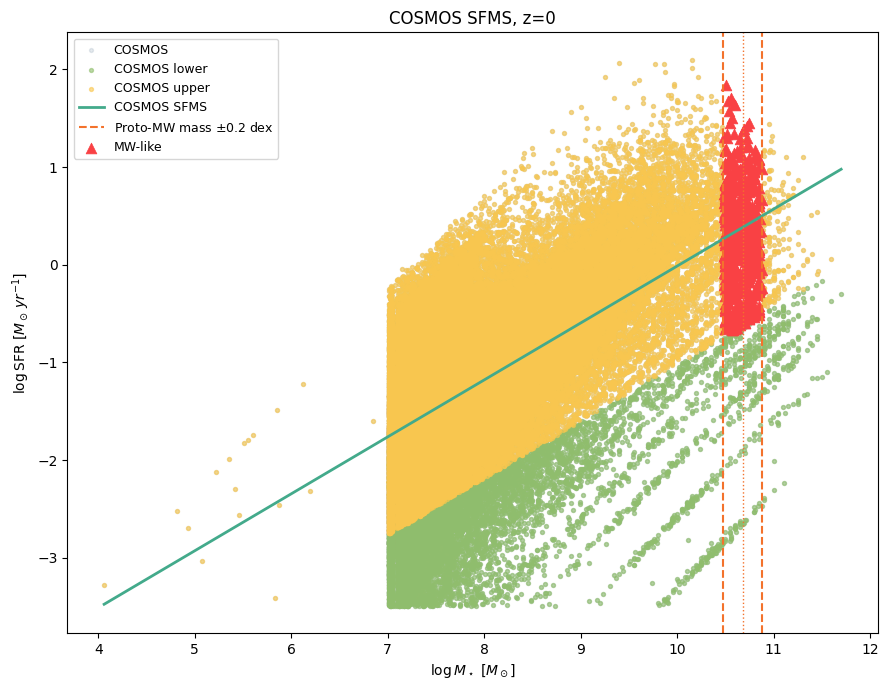


COSMOS | z ≈ 1
Ukupan broj COSMOS galaksija: 124978
Upper populacija: 111153
Lower populacija: 13825
--------------------------------------------------
MW-like populacija: N = 3369
Median logSFR = 1.2100
16–84% interval = [0.3300, 1.6300]
--------------------------------------------------
SFMS nagib: 0.6110
SFMS odsečak: -5.4837


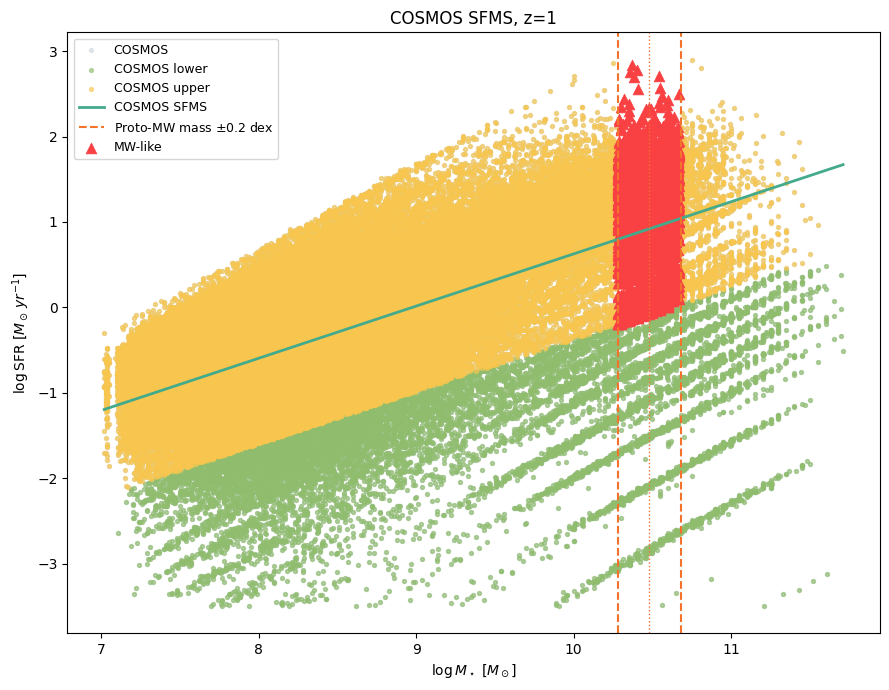


COSMOS | z ≈ 2
Ukupan broj COSMOS galaksija: 166409
Upper populacija: 153811
Lower populacija: 12598
--------------------------------------------------
MW-like populacija: N = 10103
Median logSFR = 1.5100
16–84% interval = [1.1100, 1.9400]
--------------------------------------------------
SFMS nagib: 0.6587
SFMS odsečak: -5.4334


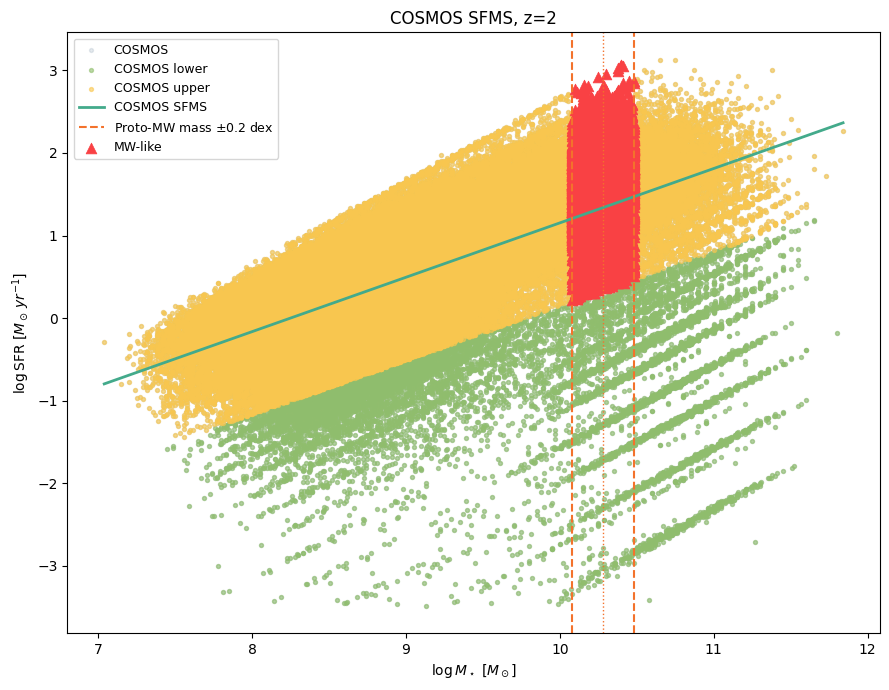


COSMOS | z ≈ 3
Ukupan broj COSMOS galaksija: 123299
Upper populacija: 118493
Lower populacija: 4806
--------------------------------------------------
MW-like populacija: N = 15482
Median logSFR = 1.3700
16–84% interval = [0.8800, 1.8300]
--------------------------------------------------
SFMS nagib: 0.6004
SFMS odsečak: -4.7110


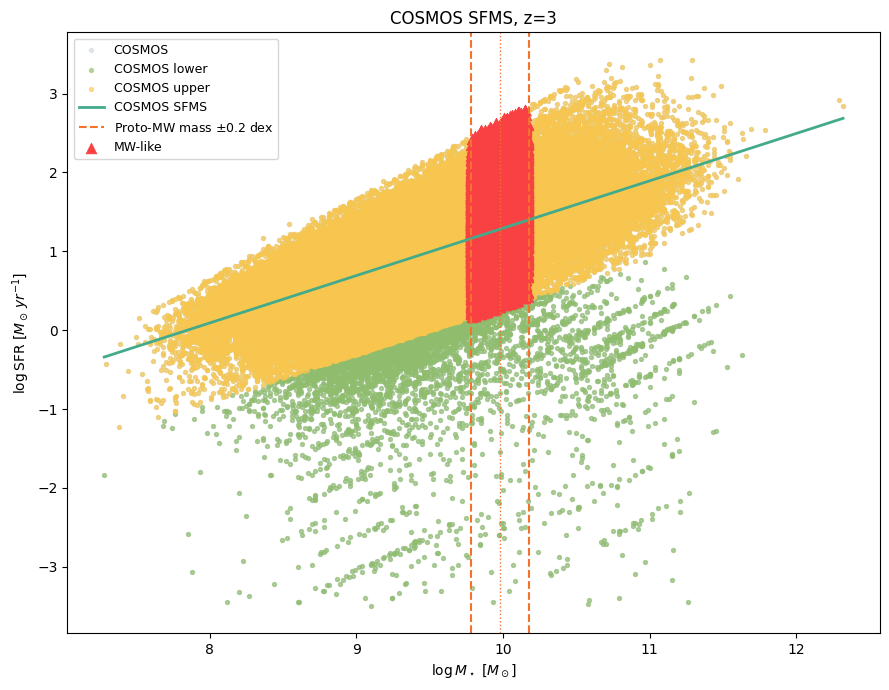

In [9]:
COSMOS_populations = {}
COSMOS_MW_statistics = {}


for z in cosmos_fits.keys():

    print()
    print("=" * 70)
    print(f"COSMOS | z ≈ {z}")
    print("=" * 70)


    cos_sub = get_cosmos_bin(z).copy()


    X = cos_sub["logM"].values.reshape(-1, 1)
    y = cos_sub["logSFR"].values

    cosmos_huber = HuberRegressor()
    cosmos_huber.fit(X, y)

    cos_sub["SFMS_fit"] = cosmos_huber.predict(X)


    cos_sub["delta_logSFR"] = (
        cos_sub["logSFR"] - cos_sub["SFMS_fit"]
    )


    upper = cos_sub[
        cos_sub["delta_logSFR"] > -1.0
    ].copy()

    lower = cos_sub[
        cos_sub["delta_logSFR"] <= -1.0
    ].copy()


    MW_mass = protoMWmass[z]

    mw_mass_like = upper[
        np.abs(
            upper["logM"] - MW_mass
        ) <= 0.2
    ].copy()


    N = len(mw_mass_like)



    mw_logSFR = mw_mass_like["logSFR"].values

    median_logSFR = np.median(mw_logSFR)

    p16 = np.percentile(mw_logSFR, 16)

    p84 = np.percentile(mw_logSFR, 84)


    

    COSMOS_populations[z] = {

        "all": cos_sub,

        "upper": upper,

        "lower": lower,

        "mw_mass_like": mw_mass_like,

        "huber": cosmos_huber
    }


    COSMOS_MW_statistics[z] = {

        "N": N,

        "median_logSFR": median_logSFR,

        "p16_logSFR": p16,

        "p84_logSFR": p84
    }
    
    
    
    print(f"Ukupan broj COSMOS galaksija: {len(cos_sub)}")

    print(f"Upper populacija: {len(upper)}")

    print(f"Lower populacija: {len(lower)}")

    print("-" * 50)

    print(f"MW-like populacija: N = {N}")

    print(f"Median logSFR = {median_logSFR:.4f}")

    print(f"16–84% interval = [{p16:.4f}, {p84:.4f}]")

    print("-" * 50)

    print(f"SFMS nagib: {cosmos_huber.coef_[0]:.4f}")

    print(f"SFMS odsečak: {cosmos_huber.intercept_:.4f}")


    plt.figure(figsize=(9, 7))


    plt.scatter(
        cos_sub["logM"],
        cos_sub["logSFR"],
        s=8,
        alpha=0.15,
        color="#577590",
        label="COSMOS"
    )


    plt.scatter(
        lower["logM"],
        lower["logSFR"],
        s=8,
        alpha=0.6,
        color="#90be6d",
        label="COSMOS lower"
    )


    plt.scatter(
        upper["logM"],
        upper["logSFR"],
        s=8,
        alpha=0.6,
        color="#f9c74f",
        label="COSMOS upper"
    )


    x_cos = np.linspace(
        cos_sub["logM"].min(),
        cos_sub["logM"].max(),
        200
    )

    y_cos = cosmos_huber.predict(
        x_cos.reshape(-1, 1)
    )

    plt.plot(
        x_cos,
        y_cos,
        color="#43aa8b",
        linewidth=2,
        label="COSMOS SFMS"
    )


    plt.axvline(
        MW_mass - 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5
    )

    plt.axvline(
        MW_mass + 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5,
        label=r"Proto-MW mass $\pm 0.2$ dex"
    )


    plt.axvline(
        MW_mass,
        color="#f3722c",
        linestyle=":",
        linewidth=1
    )


    plt.scatter(
        mw_mass_like["logM"],
        mw_mass_like["logSFR"],
        marker="^",
        s=60,
        color="#f94144",
        linewidth=0.5,
        label="MW-like"
    )


    plt.xlabel(r"$\log M_\star\ [M_\odot]$")

    plt.ylabel(r"$\log \mathrm{SFR}\ "r"[M_\odot\,yr^{-1}]$")

    plt.title(f"COSMOS SFMS, z={z}")

    plt.legend(fontsize=9)

    plt.tight_layout()

    plt.show()